In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc

from dotenv import dotenv_values

In [3]:
# Load config file agnostic to project or notebook work directory
config_path = Path("config.env")
if not config_path.exists():
    config_path = Path("../../../config.env")
CONFIG = dotenv_values(config_path)
assert CONFIG != {}, 'Configuration is empty - check the filepath.'

# Plotting defaults
MM = 1/25.4
RCPARAMS = '../../../resources/figures.mplstyle'

# Main data directory
DATADIR = Path(CONFIG['DATADIR'])

# Submodule specific data directory
OUTDIR = DATADIR / '10_analyses' / 'sexual_dimorphism'
FIGUREDIR = DATADIR / 'publication' / 'Ext_Fig_09'
FIGUREDIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Load full anndata
fp_anndata = DATADIR / '9_objects' / 'singlecell' / 'hypomap3d_singlecell_all.h5ad'
scdata = sc.read_h5ad(fp_anndata, backed='r')

In [5]:
# Define color palette
SEX_PALETTE = {
    'female': '#CC3232',
    'male': '#6290E6',
    'mixed': "#555555"
}

### Subplot A:

In [6]:
control_mask = scdata.obs['IsControl']

col_sex = scdata.obs['sex_per_sample_inferred']

order = ['female', 'male', 'mixed'][::-1]

contribution_df = pd.DataFrame(
    {
        'A': col_sex.value_counts(),
        'C': col_sex[control_mask].value_counts(),
        'NC': col_sex[~control_mask].value_counts(),
    }
).reindex(order).T

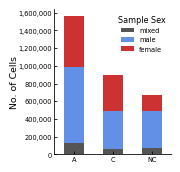

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.close('all')
with plt.style.context(RCPARAMS):
    fig, ax = plt.subplots(figsize=(40*MM, 50*MM))

    order = ['female', 'male', 'mixed'][::-1]

    contribution_df.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=[SEX_PALETTE[sex] for sex in contribution_df.columns]
    )

    ax.set_xlabel("")
    ax.set_ylabel("No. of Cells")
    ax.legend(
        title="Sample Sex",
        fontsize=5,
        title_fontsize=6,
    )
    
    # Horizontal x tick labels
    ax.tick_params(axis="x", labelrotation=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    # ax.ticklabel_format(axis="y", style="plain")

    # plt.tight_layout()
    fig.savefig(
        FIGUREDIR / "subplot_a_ALLvCvNC.pdf",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )

    plt.show()

### Subplot B: 

In [9]:
# Susbet to control anndata
scdata_control = scdata[scdata.obs['IsControl']]
scdata_control

View of AnnData object with n_obs × n_vars = 896959 × 56939 backed at '/REDACTED-path/HypoMap3D-data/v0.9/9_objects/singlecell/hypomap3d_singlecell_all.h5ad'
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_spatial_umap', 'X_umap'

In [ ]:
sample_obs = scdata_control.obs[['Dataset', 'Sample', 'sex_per_sample_inferred']].reset_index(drop=True).drop_duplicates()

assert len(sample_obs) == sample_obs['Sample'].nunique(), 'Sample information is not unique...'

sample_obs = sample_obs.reset_index(drop=True)

sample_obs.head(3)

,Dataset,Sample,sex_per_sample_inferred
0,SC1-01,SC1-01_SAMN18754353,male
1,SC1-01,SC1-01_SAMN18754354,male
2,SC1-01,SC1-01_SAMN18754356,female


/REDACTED-path/.temp/ipykernel_2915515/1485711851.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("Dataset")["sex_per_sample_inferred"]


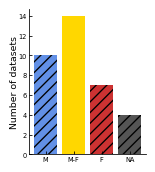

In [47]:
BAR_PALETTE = {
    "NA": "#555555",
    "M-F": "gold",
    "F": "#CC3232",
    "M": "#6290E6",
}

def classify_dataset(x):
    sexes = set(x.dropna())

    # Ignore per-sample "mixed" labels
    sexes.discard("mixed")

    if sexes == {"male"}:
        return "M"
    elif sexes == {"female"}:
        return "F"
    elif sexes == {"male", "female"}:
        return "M-F"
    else:
        return "NA"

dataset_class = (
    sample_obs
    .groupby("Dataset")["sex_per_sample_inferred"]
    .apply(classify_dataset)
)

counts = (
    dataset_class
    .value_counts()
    .reindex(["M", "M-F", "F", "NA"], fill_value=0)
)

plt.close('all')
with plt.style.context(RCPARAMS):
    fig, ax = plt.subplots(figsize=(40*MM, 50*MM))


    ax.bar(
        counts.index,
        counts.values,
        color=[BAR_PALETTE[k] for k in counts.index],
        hatch=["///" if k != "M-F" else None for k in counts.index],
    )

    ax.set_ylabel("Number of datasets")
    ax.set_xlabel("")
    
    fig.savefig(
        FIGUREDIR / "subplot_b_n_datasets.pdf",
        transparent=True,
        bbox_inches="tight",
        pad_inches=0.01,
        dpi=300
    )

    plt.show()